# 基本クラスタ量をColabで見る（H₂を使わない解析）

**「ランタイム → すべてのセルを実行」**で、今回の18,300試料（L=32,64,128、各占有率100試料）から7種類の図を作ります。CPUで実行できます。

シミュレーションは再実行せず、保存済みの試料別 `samples.csv` を再集計します。`summary.csv` や `size_relation.csv` ではありません。

初回のみ、Driveに入力がなければPCの今回の結果フォルダにある **samples.csv** をアップロードしてください。以降はDriveの保存済み入力を使います。図・CSV・報告用の説明文をDriveに保存し、最後に共有用ZIPをダウンロードできます。


In [5]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/tetra-peg-network/cluster_basics')
ROOT.mkdir(parents=True, exist_ok=True)
# 別の場所に入力がある場合は、そのsamples.csvのパスに変更します。
INPUT = ROOT / 'samples.csv'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. 入力データの選択

既定の保存先に入力がなければ、以前の `h2_report/samples.csv` も確認します。どちらにもなければ、ファイル選択で `samples.csv` をアップロードします。入力が既にあれば選択操作はありません。


In [6]:
from google.colab import files
import csv
import hashlib

if not INPUT.is_file():
    previous_input = ROOT.parent / 'h2_report' / 'samples.csv'
    if previous_input.is_file():
        INPUT = previous_input
    else:
        print('今回の100試料/条件の結果フォルダにある samples.csv を選択してください。')
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('samples.csvを1ファイルだけ選択してください。')
        name, data = next(iter(uploaded.items()))
        if Path(name).name != 'samples.csv':
            raise ValueError('summary.csv等ではなく、samples.csvを選択してください。')
        # 不正なファイルを既定の保存先に残さないため、列・件数を先に確認。
        import io
        reader = csv.DictReader(io.StringIO(data.decode('utf-8-sig')))
        required = {'L', 'target_phi', 'actual_phi', 'N', 'N1', 'bonds', 'clusters',
                    'cluster_number_mean', 'cluster_weighted_all',
                    'cluster_weighted_excl_one', 'seed'}
        if not required.issubset(set(reader.fieldnames or [])):
            raise ValueError('試料別CSVの必須列がありません。今回のsamples.csvを確認してください。')
        rows = list(reader)
        from collections import Counter
        counts = Counter((int(r['L']), round(float(r['target_phi']), 8)) for r in rows)
        expected = {(L, round(k/100, 8)) for L in (32,64,128) for k in range(10,71)}
        if set(counts) != expected or any(n != 100 for n in counts.values()):
            raise ValueError('今回の183条件・各100試料と一致しません。入力ファイルを確認してください。')
        INPUT.parent.mkdir(parents=True, exist_ok=True)
        INPUT.write_bytes(data)
        del uploaded, data, rows
print('入力:', INPUT)
print('入力SHA256:', hashlib.sha256(INPUT.read_bytes()).hexdigest())


入力: /content/drive/MyDrive/tetra-peg-network/cluster_basics/samples.csv
入力SHA256: 759674a0d77505d3c3580f967e6e814d9e12e28373993fae25d173a8ec126af3


## 2. PC版と同じコード・設定を取得

コードと設定を同じGitHubコミットに固定し、SHA256も確認します。図は平均±標準誤差（SE）です。


In [7]:
import urllib.request
import subprocess
import sys

REPOSITORY = 'takakei510/tetra-peg-network'
REVISION = '264b9d5bf24b765dc031b2ccc47622241e0ab300'
WORK = Path('/content/cluster_basics_code') / REVISION
WORK.mkdir(parents=True, exist_ok=True)
SOURCES = {
    'script': ('scripts/analysis/plot_cluster_basics.py', '2468d7c2be665437e258cea174c5f435017c21e6d569248da425dda783dd08a4'),
    'config': ('configs/analysis/cluster-basics.json', '5687a6a0f8a5a8690b8085c299be04f7a06b99ed3e0ecd1c55468f3540d31d94'),
}
local_files = {}
for key, (remote, expected_sha) in SOURCES.items():
    url = f'https://raw.githubusercontent.com/{REPOSITORY}/{REVISION}/{remote}'
    with urllib.request.urlopen(url, timeout=60) as response:
        data = response.read()
    if hashlib.sha256(data).hexdigest() != expected_sha:
        raise ValueError(f'{remote} のSHA256が一致しません。')
    dest = WORK / Path(remote).name
    dest.write_bytes(data)
    local_files[key] = dest
    print('取得:', dest.name)

FONT = Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')
if not FONT.is_file():
    subprocess.run(['apt-get', '-qq', 'update'], check=True)
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-noto-cjk'], check=True)
if not FONT.is_file():
    raise FileNotFoundError('日本語フォントの準備に失敗しました。')


取得: plot_cluster_basics.py
取得: cluster-basics.json


## 3. 作図・保存

毎回新しい日時のフォルダに保存します。入力の整合性・重複・各条件100試料を検査してから集計します。未定義の有限クラスタ平均は0に置き換えず、有効試料数をCSVに記録します。


In [8]:
from datetime import datetime
from zoneinfo import ZoneInfo

stamp = datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S_%f')
OUTPUT = ROOT / f'figures_{stamp}'
command = [sys.executable, str(local_files['script']),
           '--config', str(local_files['config']), '--results', str(INPUT),
           '--output', str(OUTPUT), '--font', str(FONT)]
subprocess.run(command, check=True)
print('コード固定コミット:', REVISION)
print('Drive保存先:', OUTPUT)


コード固定コミット: 264b9d5bf24b765dc031b2ccc47622241e0ab300
Drive保存先: /content/drive/MyDrive/tetra-peg-network/cluster_basics/figures_20261104_235010_892372


## 4. 図と目的の確認

- **最大クラスタ**：全分子のうち、どれだけが一つの集団に属するか。絶対数と割合を分けます。
- **平均サイズ**：クラスタ等重みの平均と、分子を起点とする重み付き平均を区別します。最大クラスタを除いた平均も比較します。
- **結合率・クラスタ数**：末端結合と大きな集団形成の対応、集団の個数と密度を見ます。
- **ピーク・試料数**：有限サイズによるピーク位置の違いと、今回の100試料の部分集合での平均・SEの変化を確認します。

図ごとの定義・報告での説明例・解釈の限界は、下に表示する `figure_guide.md` にあります。Sfinの最大点は有限サイズ・測定点中の最大であり、無限系の臨界点と断定しません。試料数の図は前回の5試料そのものとの比較ではありません。


### 01_largest_cluster

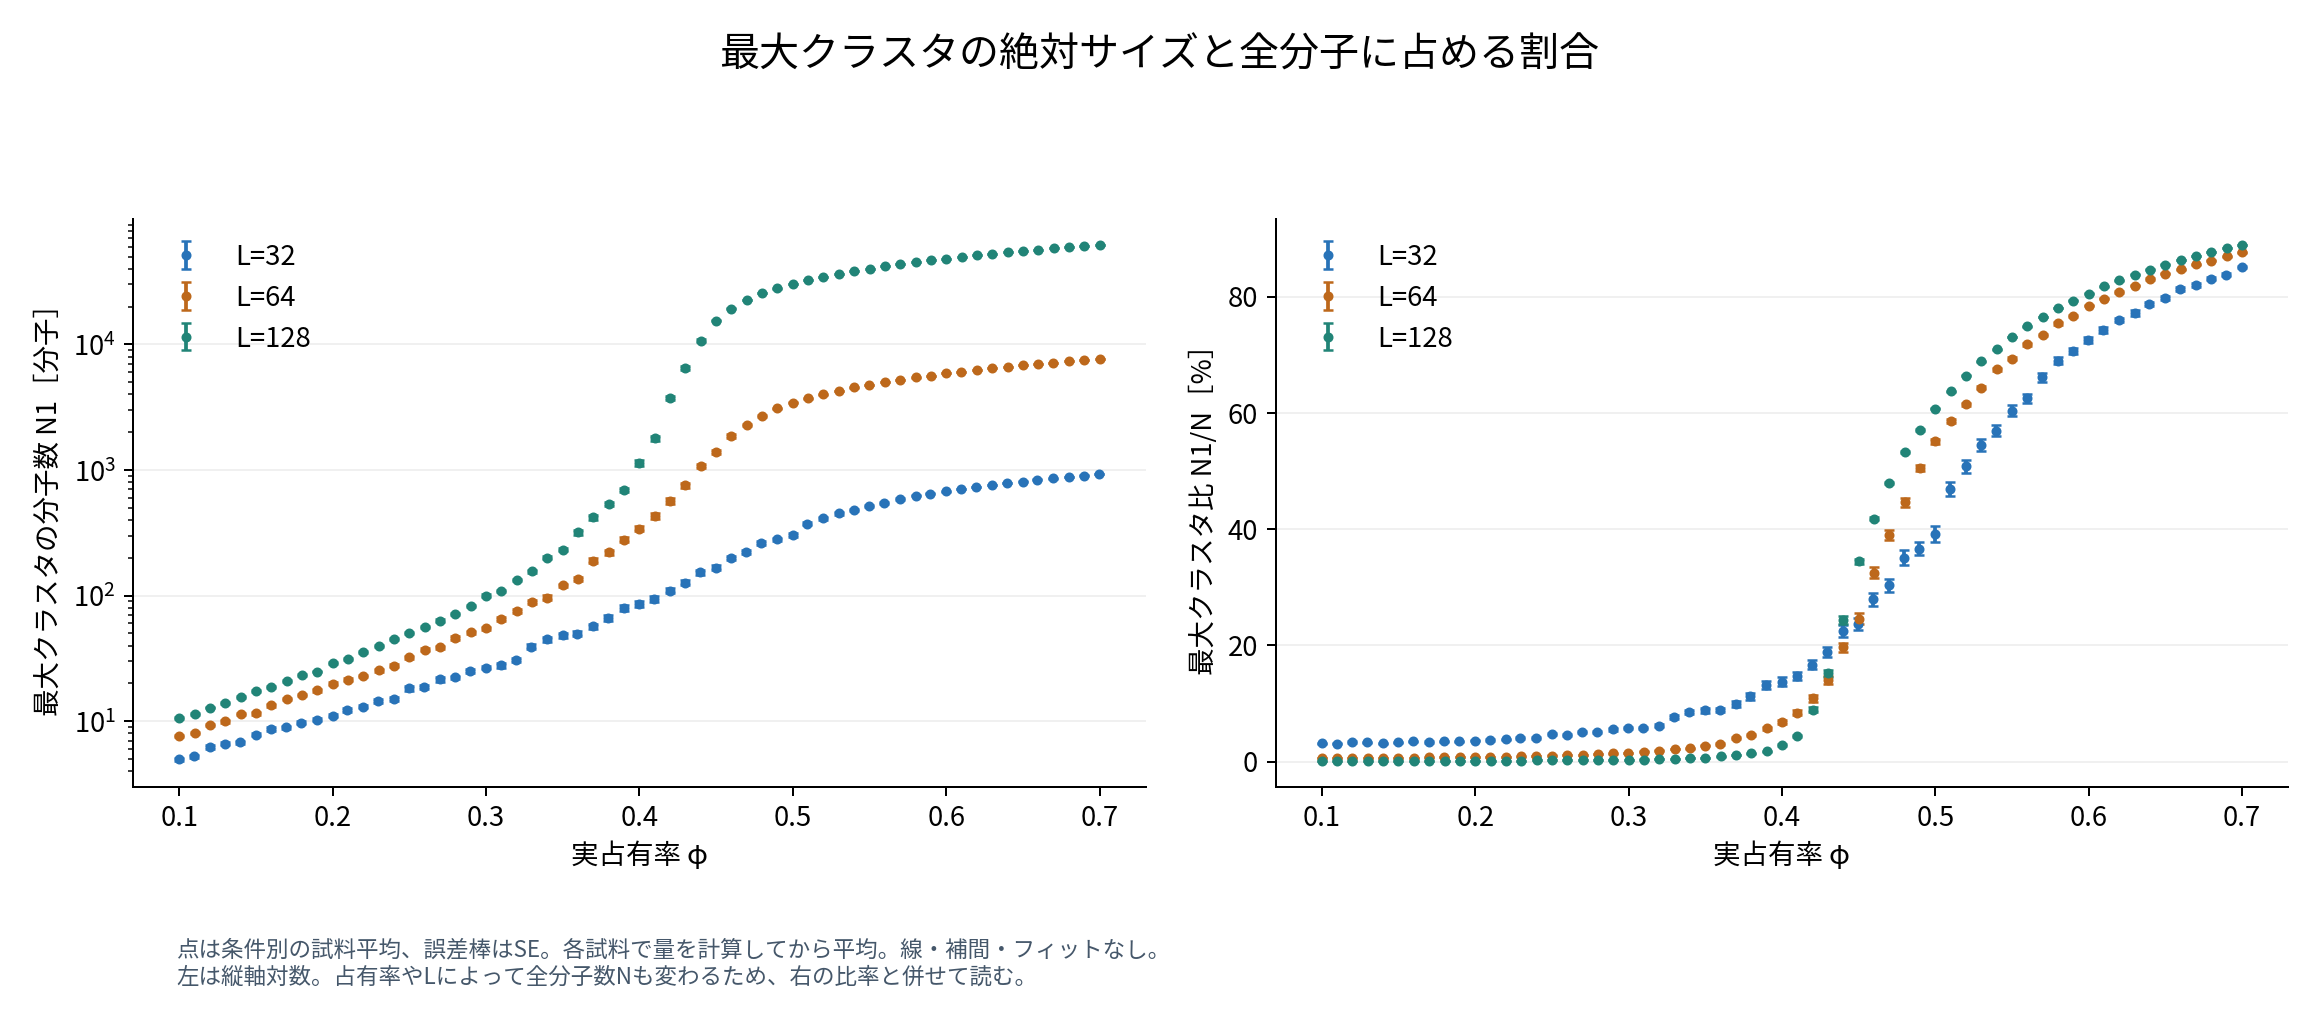

### 02_mean_cluster_sizes

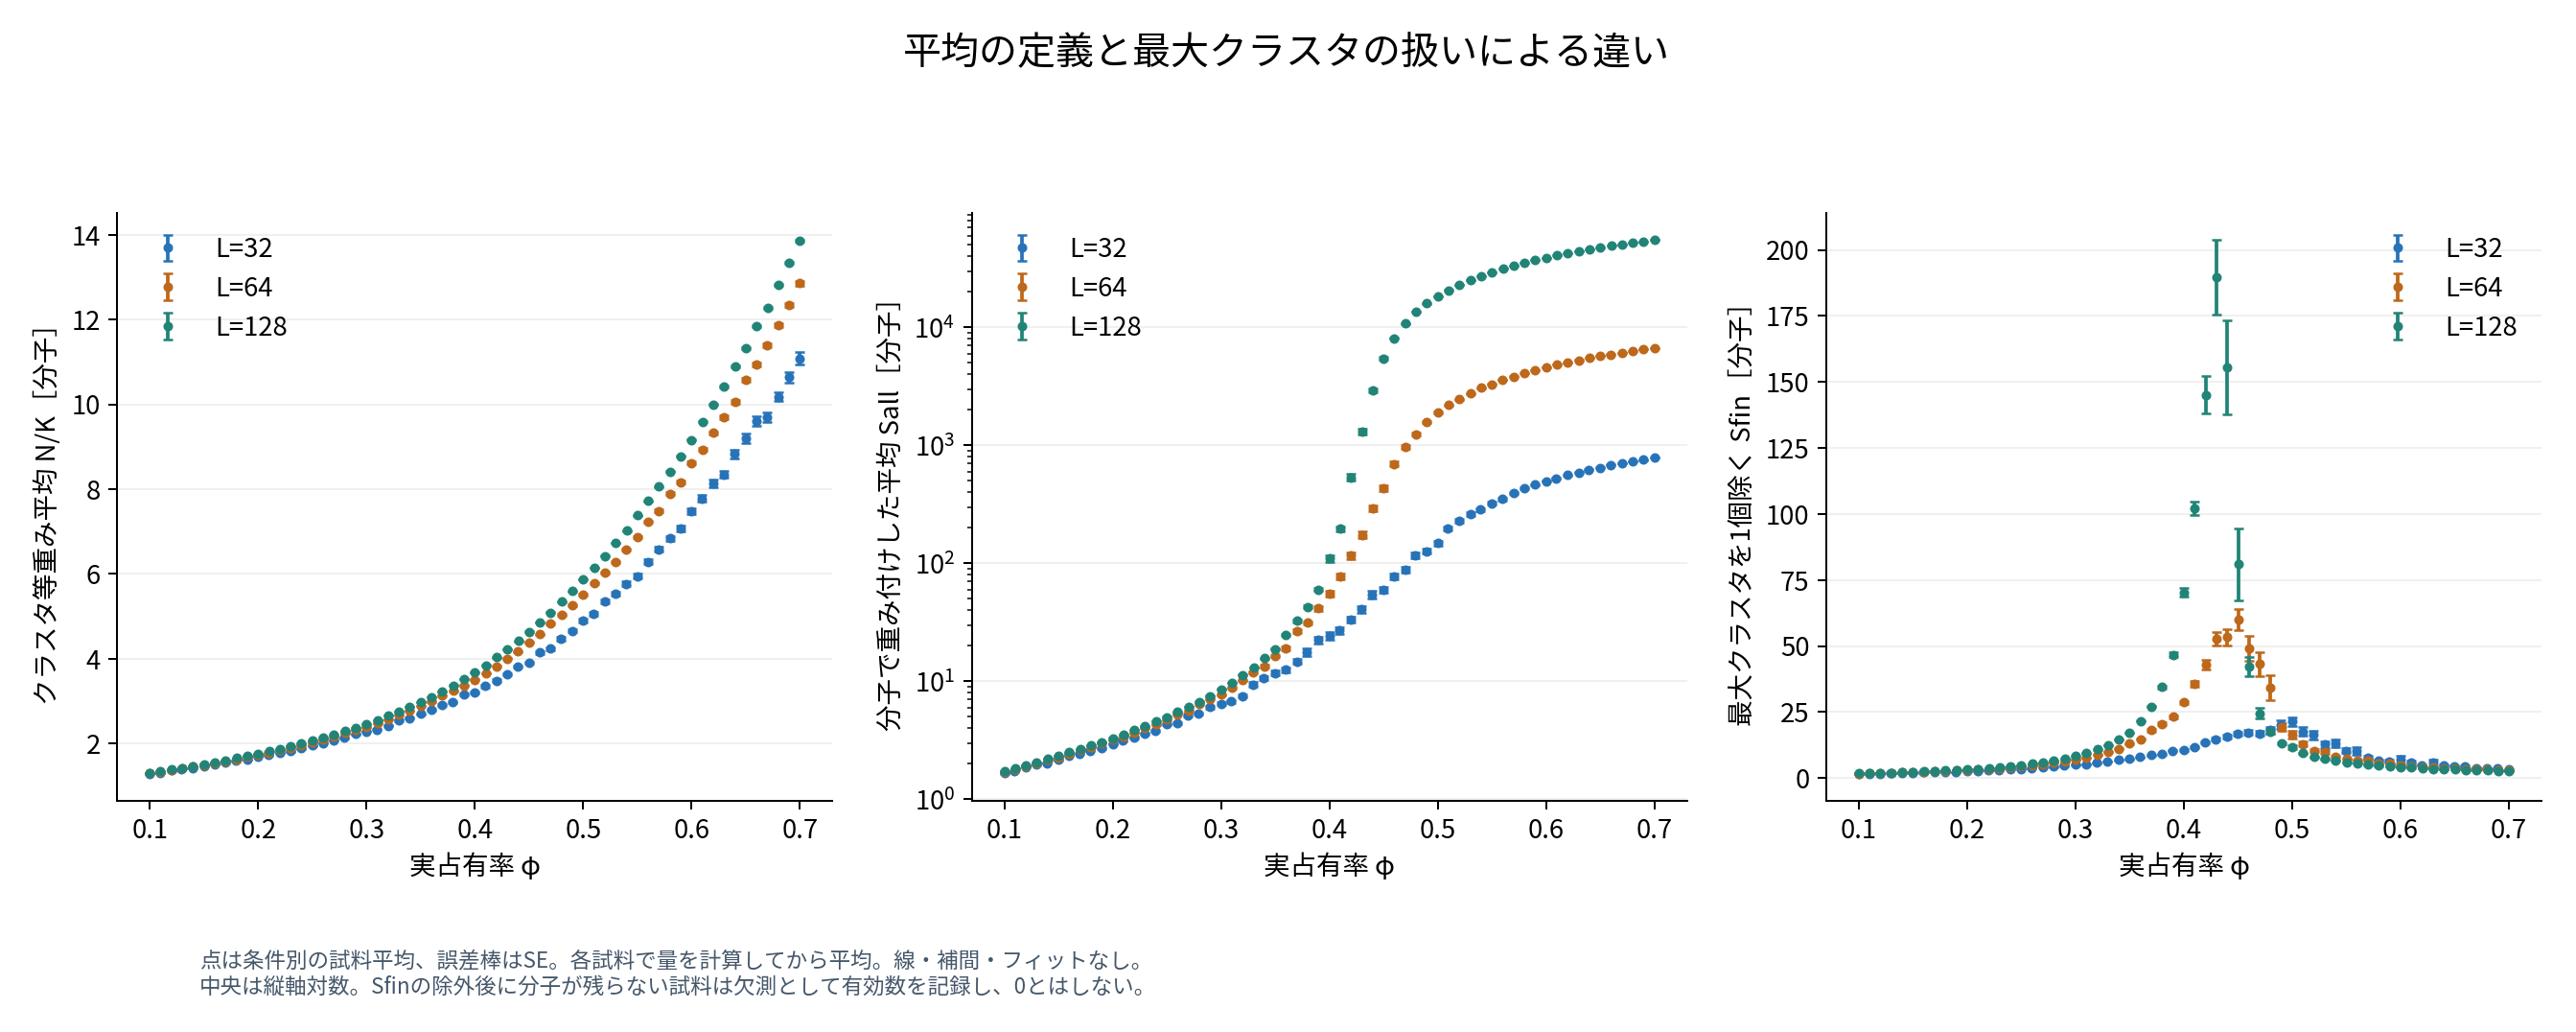

### 03_bonding_and_largest_volume

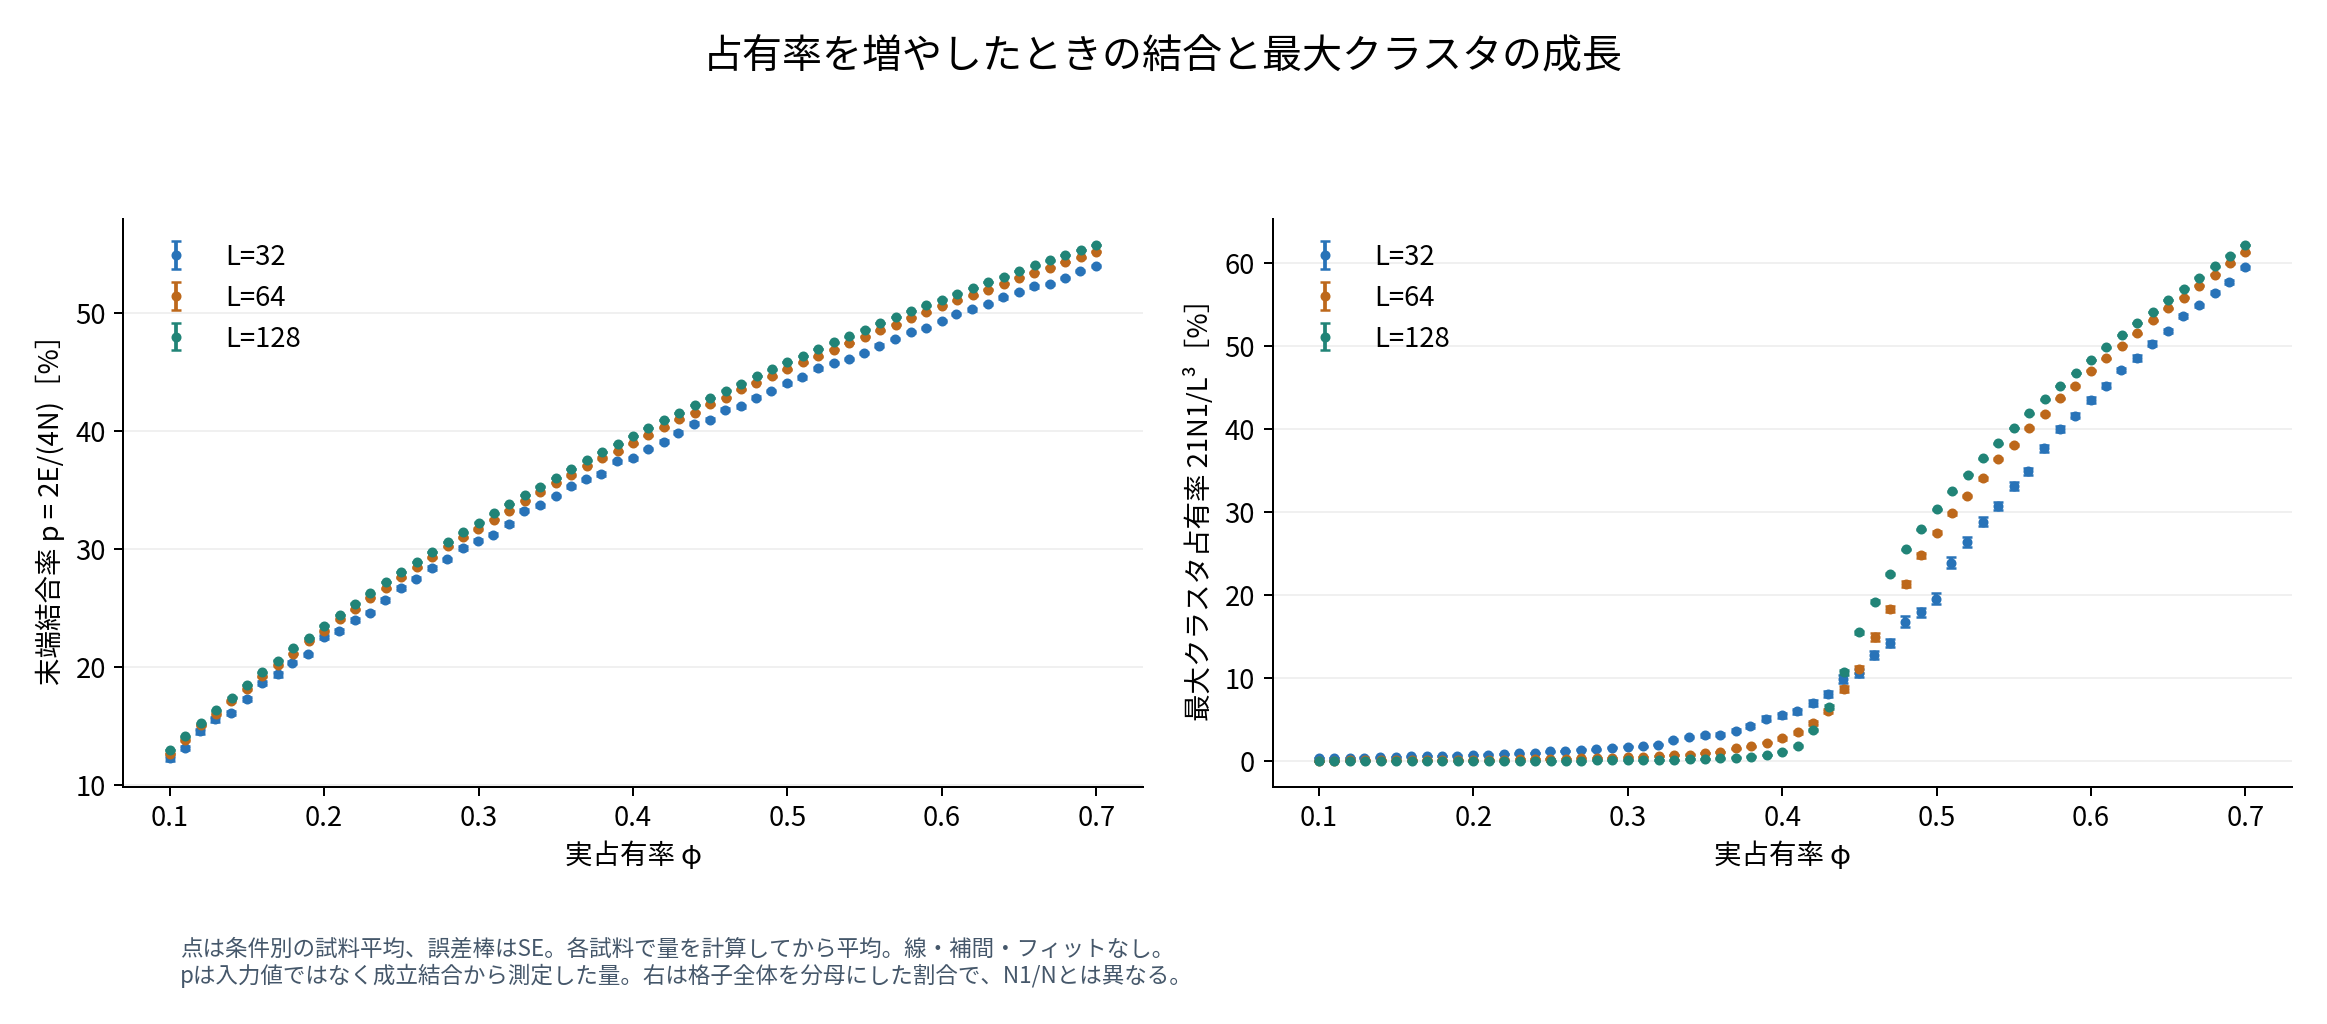

### 04_largest_volume_vs_bonding

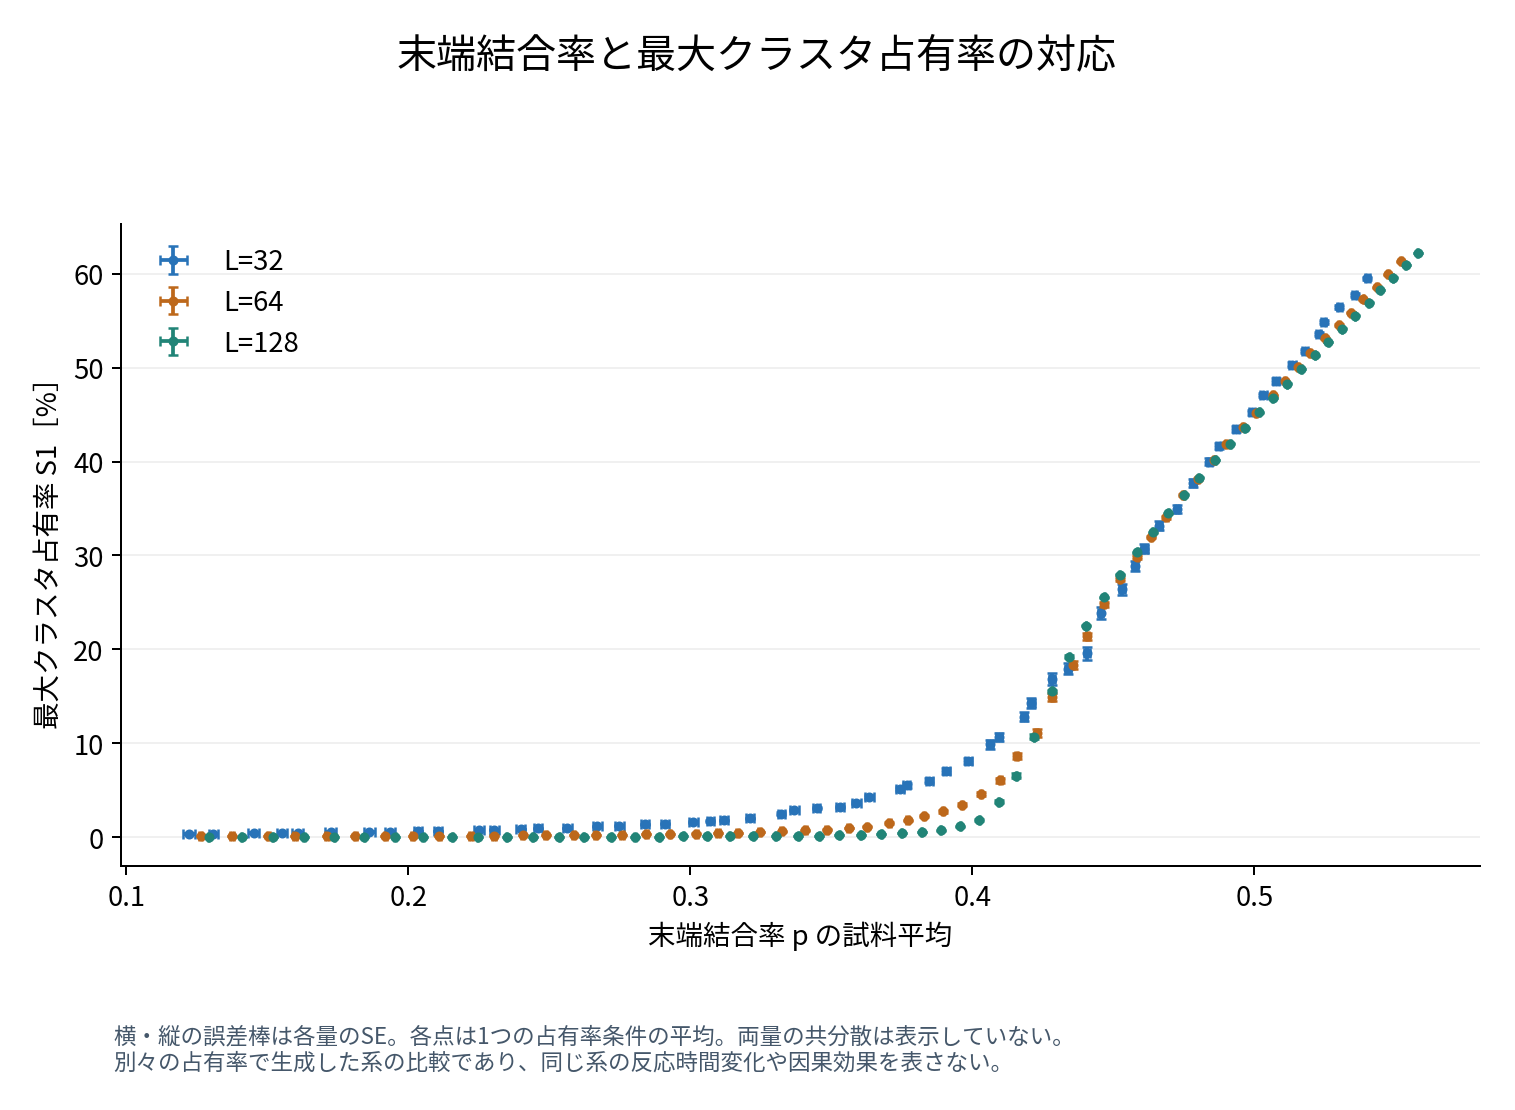

### 05_cluster_counts

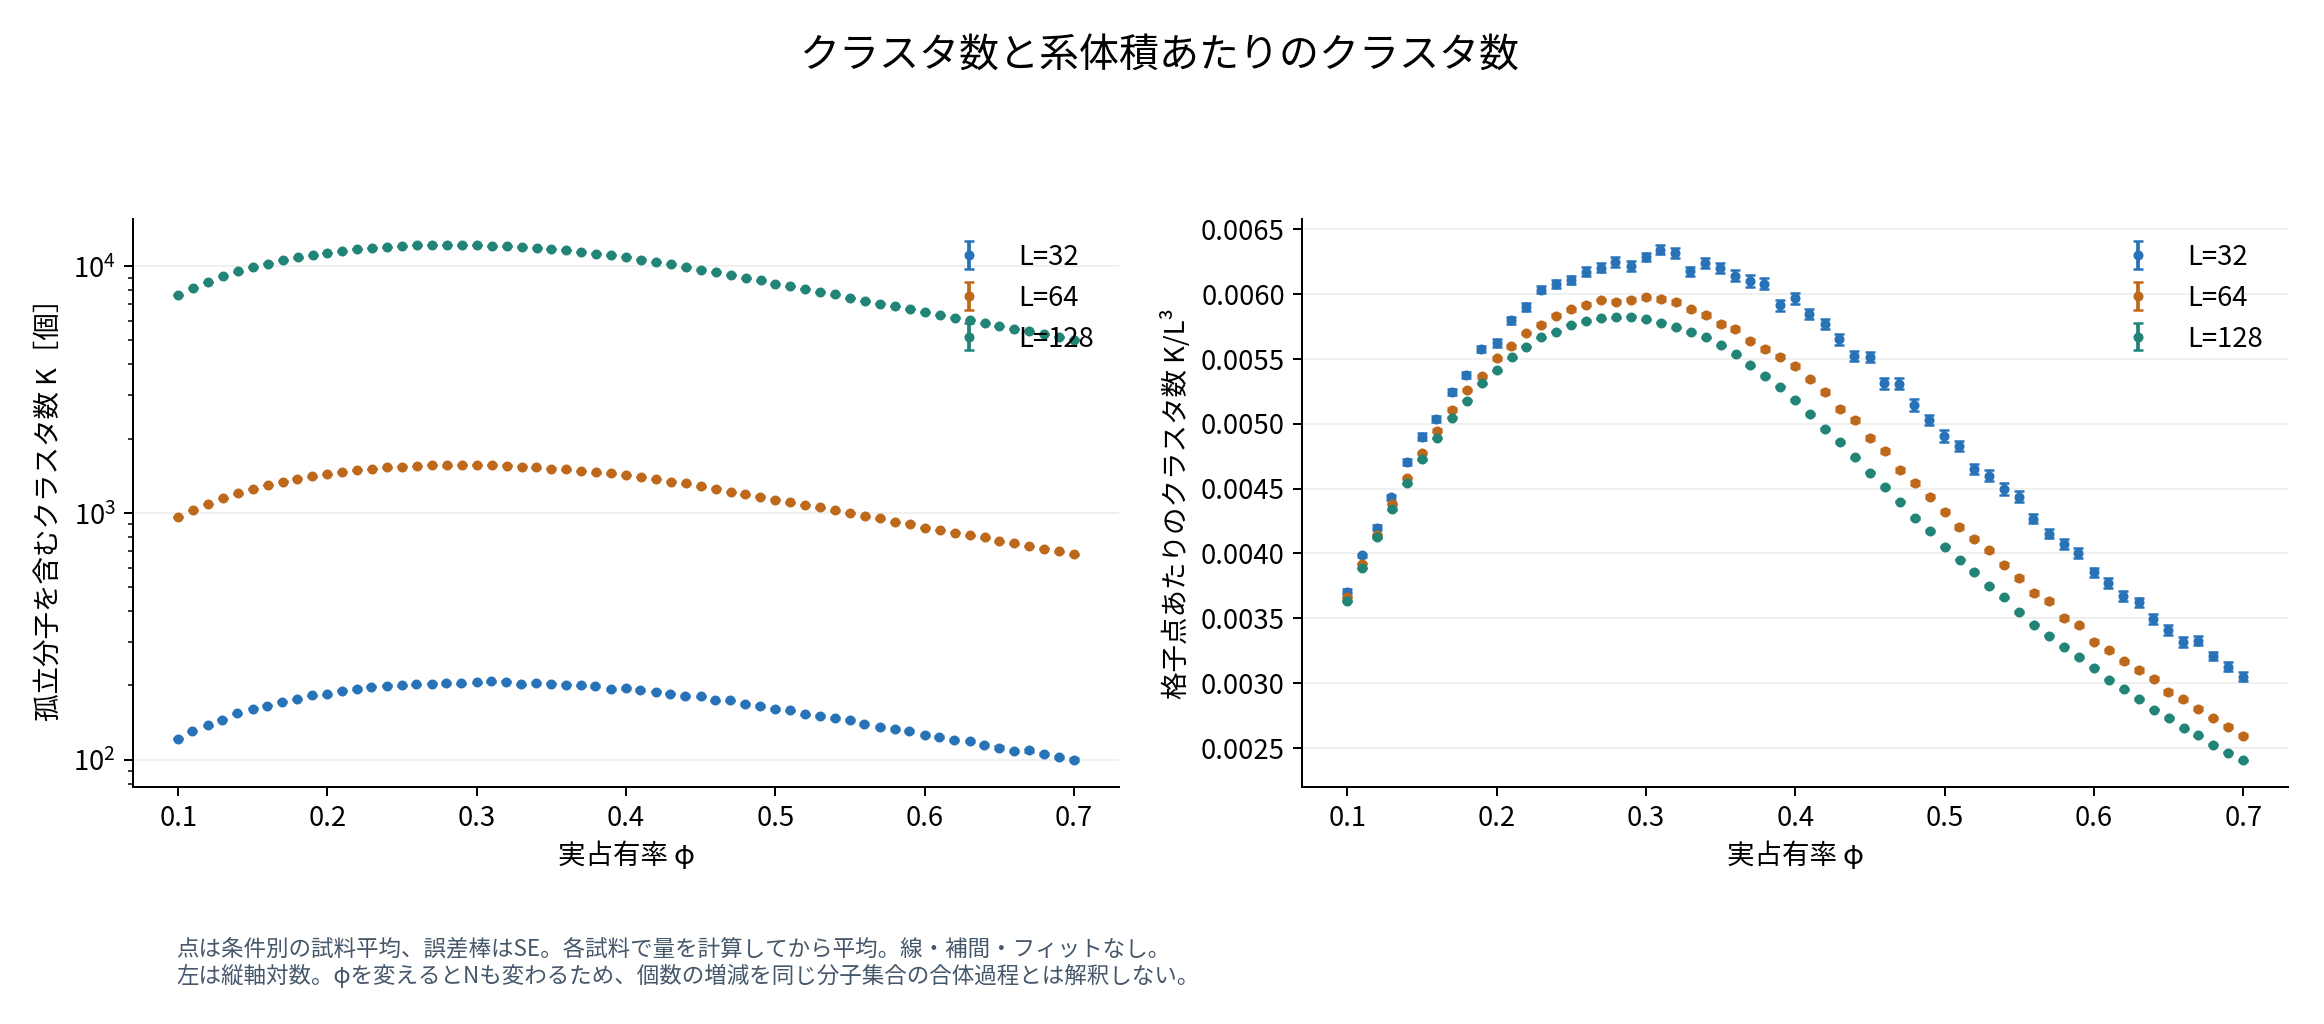

### 06_sfin_peak_region

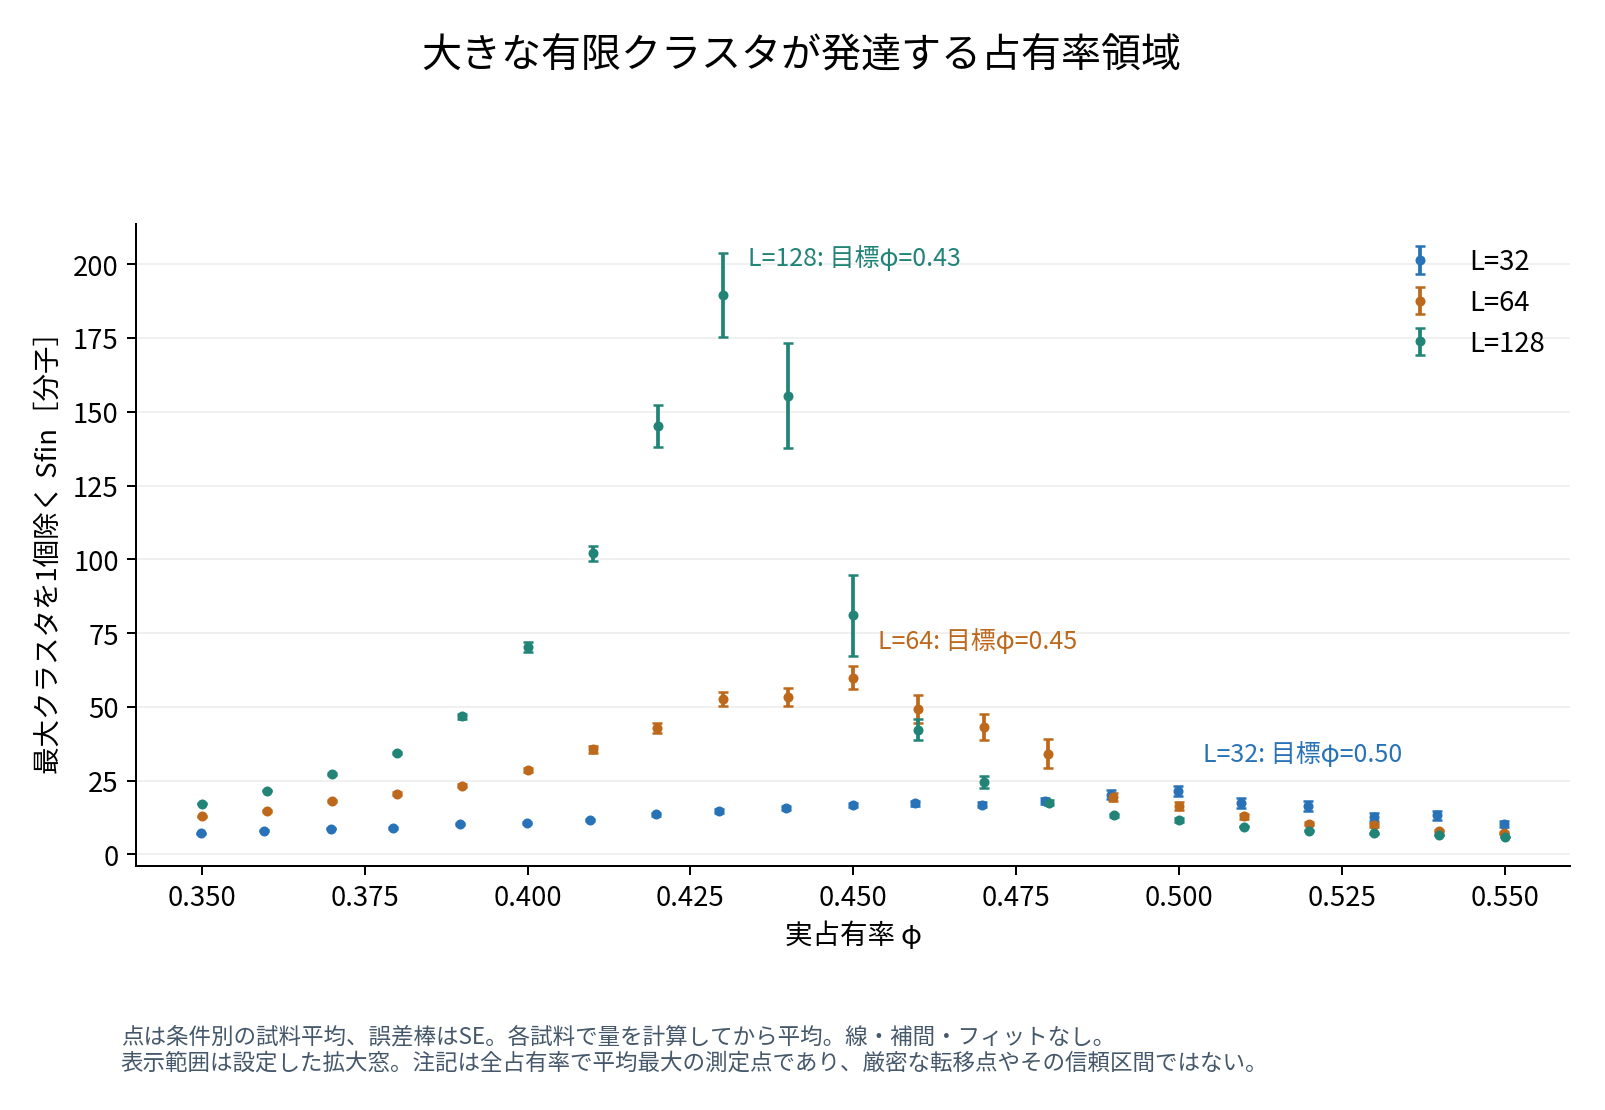

### 07_sample_count_stability

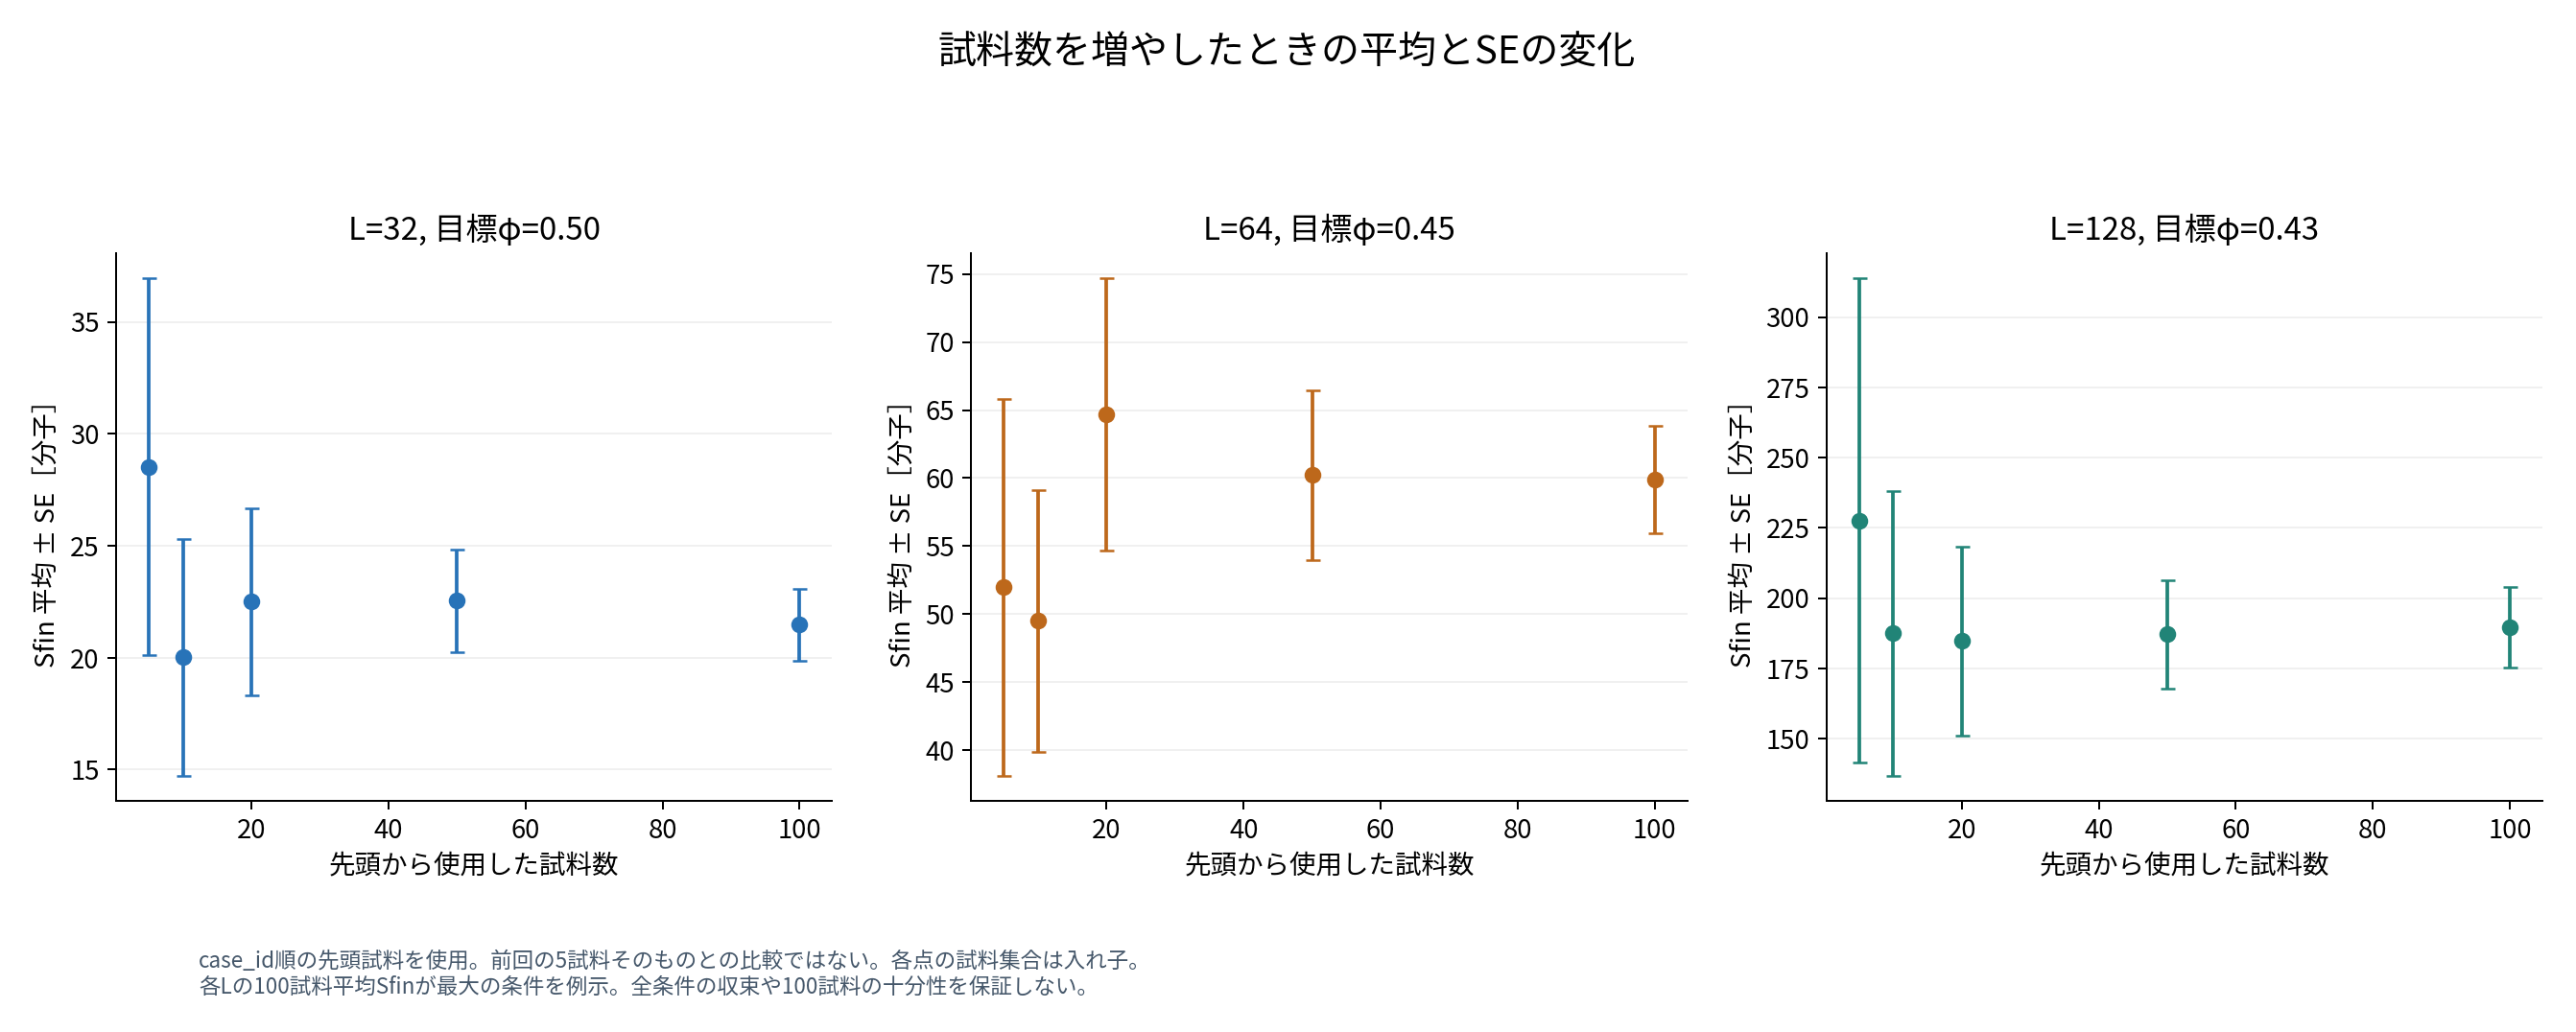

# 基本クラスタ量：目的・読み方・報告での説明

## 最初に伝える研究上の問い
占有率を変えると、分子ネットワークのつながり方はどう変化するか。また、その変化は格子サイズによってどう異なるか。
この作図はH2を入力として使わず、生成済みネットワークの基本構造を調べる。異なる占有率の試料は、同じ系を時間発展させたデータではない。

## 01 最大クラスタの絶対サイズと比率
- 目的：最も大きな集団が何分子に成長し、全分子のどれだけを含むかを確認する。
- 定義：N1は最大クラスタ分子数、Pmax=N1/N。Nは孤立分子も含む全分子数。
- 物理的意味：絶対サイズだけだと大きな系が有利なので、比率を併せて比較する。
- 説明例：「占有率の増加に伴って、最大クラスタが全分子のどの程度を占めるようになるかを調べました。系サイズが違うため、絶対分子数と比率を分けています。」
- 限界：有限系でPmaxが大きくなることだけでは、無限系の転移点・貫通・ゲルの弾性を確定できない。

## 02 平均クラスタサイズの3つの定義
- A=N/Kはクラスタを1個選んだときの平均分子数。孤立分子が多いと小さくなる。
- Sall=Σs²/Nは分子を1個選んだとき、それが属するクラスタの平均分子数。最大クラスタも含み、高占有率ではその寄与が大きい。
- Sfin=Σ′s²/Σ′sは最大クラスタ1個を除いた同種の平均。除外後に残る分子から1個選んだときの所属クラスタの平均サイズ。
- 目的：最大クラスタの成長と、それ以外の集団の発達を分けて見る。
- 説明例：「巨大なクラスタができた後は、それを含む平均が支配されます。そこで、最大クラスタを除いた平均も調べ、周囲に残るクラスタの発達を見ました。」
- 限界：Sfinはクラスタの個数ではない。大きな第2・第3クラスタも二乗で強く寄与する。同率最大は1個だけ除く。

## 03 占有率と末端結合率・最大クラスタ占有率
- 目的：分子を多く配置したとき、末端の結合がどれだけ増え、格子全体に対して最大クラスタがどれだけ大きくなるかを見る。
- 定義：p=2E/(4N)、S1=21N1/L³。前者の分母は全末端、後者は全格子点。
- 説明例：「分子濃度を増やした結果として結合率pがどう変化するかと、大きな集団の形成を比較しました。」
- 限界：pは独立に設定した反応確率ではなく測定結果。S1=φPmaxは各試料で成り立つが、別々に平均した量の積が平均S1に一致するとは限らない。

## 04 末端結合率と最大クラスタ占有率
- 目的：どれだけの末端が結合した状態で、大きな集団が形成されるかを記述する。
- 説明例：「横軸を結合済み末端の割合に変え、結合量と大きなクラスタの形成の対応を調べました。」
- 限界：結合を増やした因果効果や時間発展ではない。pとS1は同じ試料から測定され、共分散を持つ。誤差棒は周辺SEのみ。

## 05 クラスタ数とクラスタ数密度
- 目的：集団が何個に分かれているかと、体積をそろえたときの数を確認する。
- 定義：Kは孤立分子を含むクラスタ数、K/L³は格子点あたりの数。
- 説明例：「クラスタの大きさに加え、全体が何個の集団に分かれるかを調べました。Lによる体積の違いを除くため、単位格子体積あたりの数も示します。」
- 限界：φを変えるとNも変わる。Kの増減だけで、同じ集団の合体・分裂を直接観測したとは言えない。

## 06 Sfinのピーク領域
- 目的：最大クラスタ以外にも大きな集団が発達する領域を、複数Lで比較する。
- 説明例：「Sfinの平均が最大となる占有率と、その系サイズ依存を確認しました。測定点のピークを転移候補の手がかりとして扱います。」
- 限界：ピークの位置は有限サイズ、占有率刻み、統計誤差に依存する。注記は平均の最大点で、転移点や位置の信頼区間ではない。

## 07 試料数による平均・SEの変化
- 目的：少ない試料で見えた平均が、試料追加でどの程度変わるかを見る。
- 説明例：「各Lのピーク条件を例に、5試料から100試料まで増やしたときの平均とSEを比較しました。」
- 限界：先頭試料の部分集合は互いに重なる。前回の5試料そのものとの直接比較ではなく、今回の100試料の部分集合を使う。ケースの順序にも依存する。SEが小さくても偏りは消えず、この図だけで十分な試料数とは宣言しない。

## 平均、SD、SEの区別
SDは試料間のばらつき。SE=SD/√nは試料平均の不確かさ。有効数n=100ならSE=SD/10だが、試料間のばらつき自体が10分の1になったわけではない。
すべての比率は各試料で計算してから平均する。試料のクラスタを全て合算して比を作る集計とは異なる。

## 今回のピークの観測
|L|平均Sfinが最大の目標占有率|平均 ± SE [分子]|試料SD [分子]|
|---:|---:|---:|---:|
|32|0.50|21.47 ± 1.60|15.97|
|64|0.45|59.88 ± 3.95|39.48|
|128|0.43|189.60 ± 14.20|142.03|

この表の最大点は全占有率から選択した記述的な結果。隣接点との差の有意性や、無限系の臨界点を示す表ではない。
生成・結合規則を変えず、保存済みsamples.csvから再集計した。元の結合・クラスタCSVからネットワーク構造を独立に再検証したという意味ではない。


In [9]:
from IPython.display import display, Image, Markdown

for image_path in sorted(OUTPUT.glob('*.png')):
    display(Markdown(f'### {image_path.stem}'))
    display(Image(filename=str(image_path)))
display(Markdown((OUTPUT / 'figure_guide.md').read_text(encoding='utf-8')))


## 5. ChatGPTへ結果を共有

下のボタンで `cluster_basics_share.zip` をダウンロードし、チャットに添付してください。7種類のPNG/SVG、集計CSV、図の説明、入力とコードのSHA256を含む実行記録が入っています。同じZIPはDriveの今回の出力フォルダにもあります。


In [10]:
import ipywidgets as widgets

archive = OUTPUT / 'cluster_basics_share.zip'
button = widgets.Button(description='共有用ZIPをダウンロード', layout=widgets.Layout(width='260px'))
button.on_click(lambda _: files.download(str(archive)))
display(button)
print('ZIP:', archive)


Button(description='共有用ZIPをダウンロード', layout=Layout(width='260px'), style=ButtonStyle())

ZIP: /content/drive/MyDrive/tetra-peg-network/cluster_basics/figures_20261104_235010_892372/cluster_basics_share.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>